# **Sentiment Analysis On Amazon Review**

### import all the necessary libraries

In [ ]:
import re
import nltk
import wordcloud
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import precision_score,recall_score,accuracy_score

nltk.download('stopwords')
nltk.download('wordnet')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

# **Step-1 Upload the data and analyze it**

In [ ]:
df=pd.read_csv("/content/Reviews.csv")

In [ ]:
df.head(5)

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [ ]:
df.shape

(568454, 10)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


In [ ]:
df.describe()

,Id,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time
count,568454.000000,568454.000000,568454.00000,568454.000000,5.684540e+05
mean,284227.500000,1.743817,2.22881,4.183199,1.296257e+09
std,164098.679298,7.636513,8.28974,1.310436,4.804331e+07
min,1.000000,0.000000,0.00000,1.000000,9.393408e+08
25%,142114.250000,0.000000,0.00000,4.000000,1.271290e+09
50%,284227.500000,0.000000,1.00000,5.000000,1.311120e+09
75%,426340.750000,2.000000,2.00000,5.000000,1.332720e+09
max,568454.000000,866.000000,923.00000,5.000000,1.351210e+09


In [ ]:
# check for the null values
df.isnull().sum()

,0
Id,0
ProductId,0
UserId,0
ProfileName,26
HelpfulnessNumerator,0
HelpfulnessDenominator,0
Score,0
Time,0
Summary,27
Text,0


In [ ]:
# we can simply drop the null values as they dont effect the overall data
df.dropna(inplace=True)

In [ ]:
df.isnull().sum()

,0
Id,0
ProductId,0
UserId,0
ProfileName,0
HelpfulnessNumerator,0
HelpfulnessDenominator,0
Score,0
Time,0
Summary,0
Text,0


In [ ]:
# check for the duplicates
df.duplicated().sum()

np.int64(0)

In [ ]:
keep = ["not", "no", "nor", "never", "none", "neither",
        "very", "too", "so", "more", "most", "only", "just",
        "but", "against", "without", "until", "if"]

In [ ]:
# Removing the stop words from the one that we need
stop_words = set(stopwords.words('english')) - set(keep)

# **Text Preprocessing**

In [ ]:
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()                          # lower case
    text = re.sub(r"<.*?>", " ", text)                # remove HTML tags
    text = re.sub(r"https?\S+|www\.\S+", " ", text)   # remove URLs
    text = re.sub(r"[^a-z\s]", " ", text)             # remove punctuation and digits
    tokens = text.split()
    tokens = [w for w in tokens if w not in stop_words and len(w) > 1]  # stop words

    filtered = []
    for w in tokens:
        word = lemmatizer.lemmatize(w, "v")           # verb
        word = lemmatizer.lemmatize(word, "n")        # noun
        word = lemmatizer.lemmatize(word, "a")        # adjective
        filtered.append(word)

    return " ".join(filtered)

df["CleanText"] = df["Text"].apply(preprocess_text)

# **Explorative Data Analysis**

## **Distribution Of Rating**

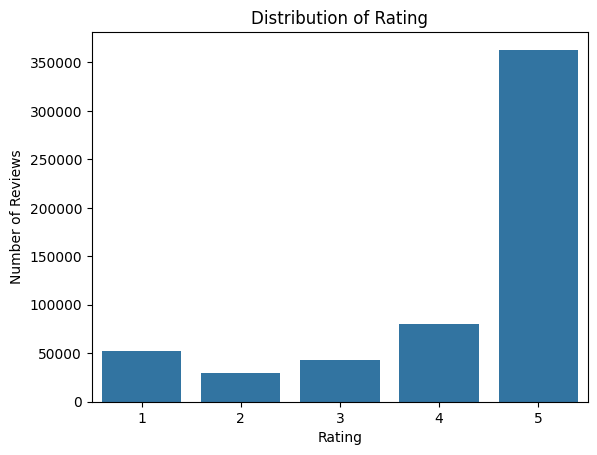

In [ ]:
sns.countplot(data=df, x="Score")
plt.title("Distribution of Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

### **Insights**
1.Rating 5 has about 360,000 reviews, far more than any other rating. That's roughly 64% of the data, and 4 and 5 stars together are about 78%. Customers who leave reviews on this site are mostly satisfied

## **Rating Percentage Distribution**

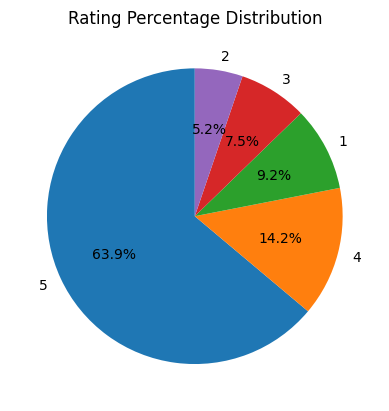

In [ ]:
pct = df["Score"].value_counts()
pct.plot.pie(autopct="%1.1f%%", startangle=90)
plt.title("Rating Percentage Distribution")
plt.ylabel("")
plt.show()

### **Insights**
1. Nearly two out of every three reviews give the top rating. This means customers on this site are mostly happy with the food products they buy. It also means the dataset isn't a fair mix of opinions, because satisfied customers are far more likely to leave a review than unhappy ones.

2. Positive reviews outnumber negative ones by more than 5 to 1. In the sentiment categories you'll create (Positive: 4-5, Neutral: 3, Negative: 1-2), this means Positive will be by far the biggest group. Overall, customers are satisfied with the products, and the small share of negative reviews likely points to specific problems like poor quality, wrong items, or damaged packages. It's worth reading these reviews in the word cloud and the negative-word char

## **Word Cloud For Positive Reviews**

In [ ]:
df_positive = df[df["Score"] > 3]
positive_text =df_positive["CleanText"]
positive_text = " ".join(positive_text)

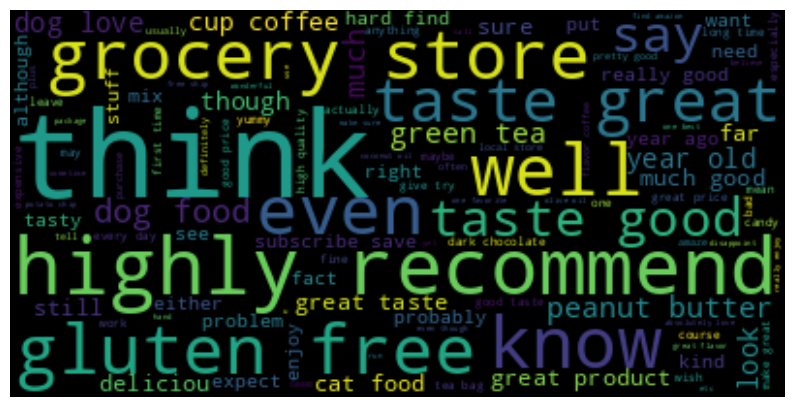

In [ ]:
wc=wordcloud.WordCloud()
image=wc.generate(positive_text)
plt.figure(figsize=(10,10))
plt.imshow(image, interpolation='bilinear')
plt.axis('off')
plt.show()

## **Word Cloud For  Negative Reviews**

In [ ]:
df_negative = df[df['Score']<3]
negative_text = df_negative['CleanText']
negative_text = ' '.join(negative_text)

(np.float64(-0.5), np.float64(399.5), np.float64(199.5), np.float64(-0.5))

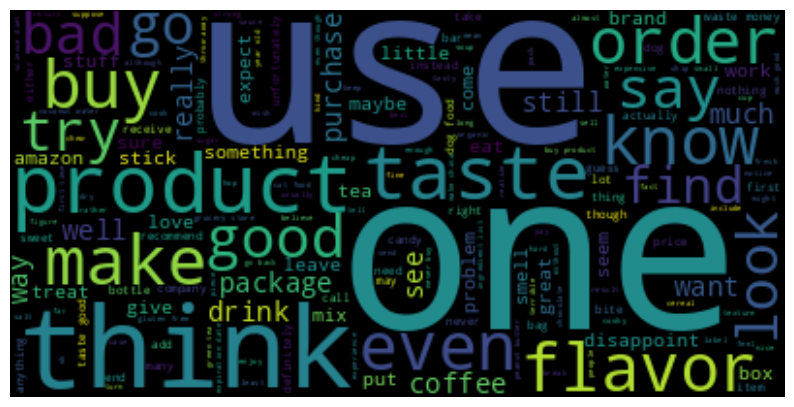

In [ ]:
image = wc.generate(negative_text)
plt.figure(figsize=(10,10))
plt.imshow(image, interpolation='bilinear')
plt.axis('off')

## **Most Frequent Words In Positive Reviews**

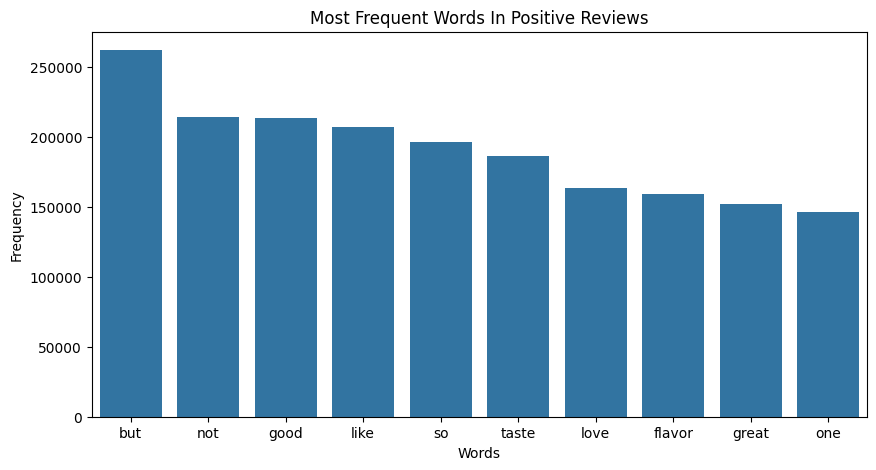

In [ ]:
positive_words = pd.Series(positive_text.split()).value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=positive_words.index, y=positive_words.values)
plt.title('Most Frequent Words In Positive Reviews')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.show()

### **Insights**
1. but (about 262k), not (about 214k) and so (about 196k) are in the top 5. These are the words we deliberately kept out of the stop-word list to protect negation and emphasis. They appear because they are very common in all English text, not because they are specific to positive reviews.

2. good (about 213k), like (about 207k), love (about 163k) and great (about 152k) show that customers use plain, favourable language when they rate a product 4 or 5 stars.

## **Most Frequent Words In Negative Reviews**

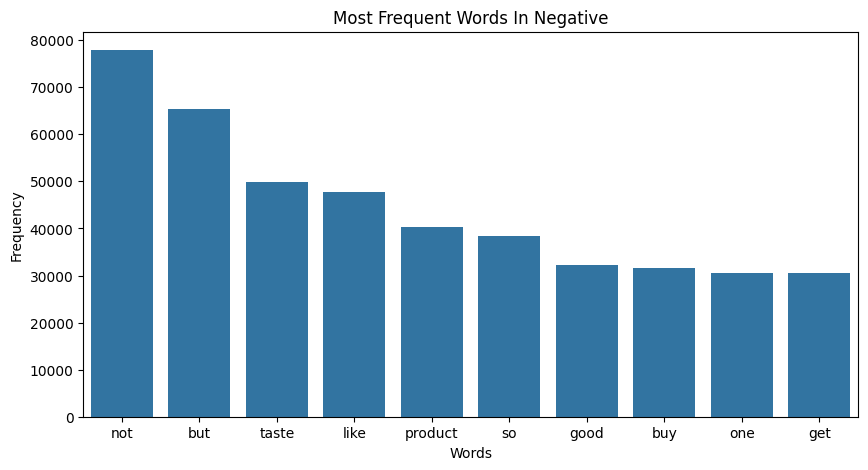

In [ ]:
negative_words = pd.Series(negative_text.split()).value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=negative_words.index, y=negative_words.values)
plt.title('Most Frequent Words In Negative')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.show()

### **Insights**
1. In positive reviews but came first and not second, but here not leads. Negation is the clearest pattern in unhappy reviews, with phrases like "did not taste good", "would not buy again" and "not as described". This confirms that keeping not in the stop-word list was the right cal

2. Taste is the main topic in both happy and unhappy reviews. In negative reviews it points to complaints like bland, bitter, stale or "tastes artificial", so flavour is what makes or breaks a food product.

##**Distribution Of Helpfull Ratio**

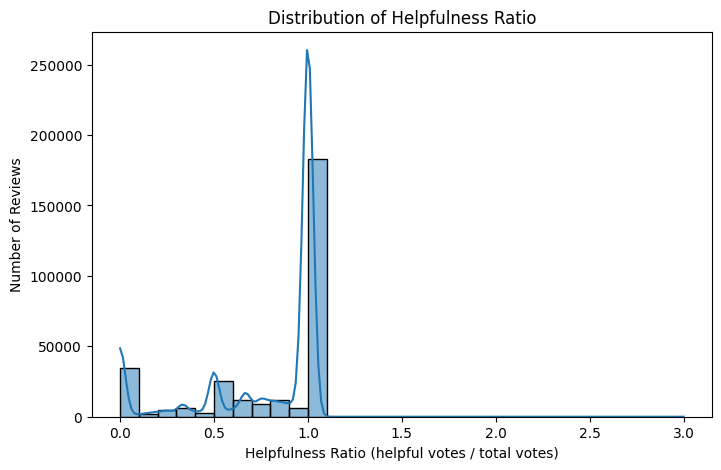

In [ ]:
df["HelpfulnessRatio"] = df["HelpfulnessNumerator"] / df["HelpfulnessDenominator"].replace(0, np.nan)
voted = df["HelpfulnessRatio"].dropna()

plt.figure(figsize=(8, 5))
sns.histplot(voted, bins=30, kde=True)
plt.title("Distribution of Helpfulness Ratio")
plt.xlabel("Helpfulness Ratio (helpful votes / total votes)")
plt.ylabel("Number of Reviews")
plt.show()

### **Insights**
1. Among reviews that got votes, most were rated helpful by everyone who voted. Readers mostly agree that reviews on this site are useful, and the distribution is strongly lopsided toward high helpfulness.

2. At 0.0 nobody found the review helpful, and at 0.5 voters were split. These spikes appear because most reviews have only a few votes, so the ratio can only take values like 0/1, 1/2 or 1/3. That also explains why the middle of the chart is thin and uneven.

3. Between 0.1 and 0.9 there are only small bars. People tend to agree on a review (all helpful or none helpful), and few reviews land in between

##**Relationship Between Rating And Helpfullness**

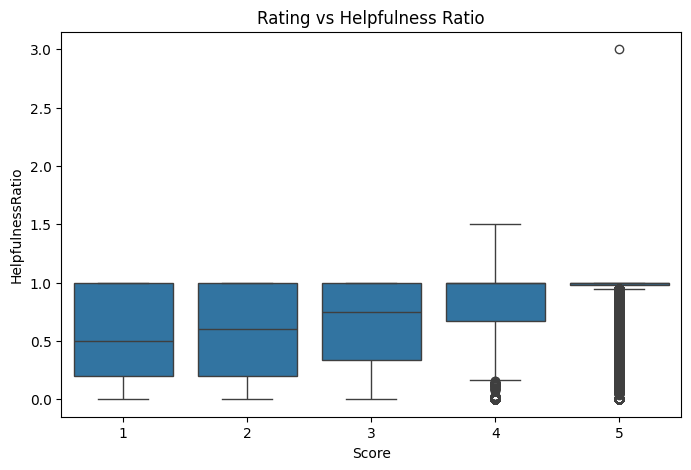

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Score", y="HelpfulnessRatio")
plt.title("Rating vs Helpfulness Ratio")
plt.show()

### **Insights**
1. The median goes from about 0.5 for 1-star to about 0.6 for 2-star, 0.75 for 3-star, and 1.0 for 4- and 5-star. Voters tend to find positive reviews more helpful than negative ones.

2. The boxes for 1-, 2- and 3-star are tall (roughly 0.2 to 1.0), so voters often disagree about these reviews. Some readers find a complaint useful while others think it is unfair or unhelpful. For 4-star the box is narrower (about 0.67 to 1.0), and for 5-star it collapses into a flat line at 1.0.

3. Most 5-star reviews that got votes have a ratio of exactly 1.0, so the box has no height. The thick black column of dots below it is the minority of 5-star reviews with low ratios. They are drawn as outliers only because the typical value is so tightly packed at 1.0.

##**Review Length Distribution**

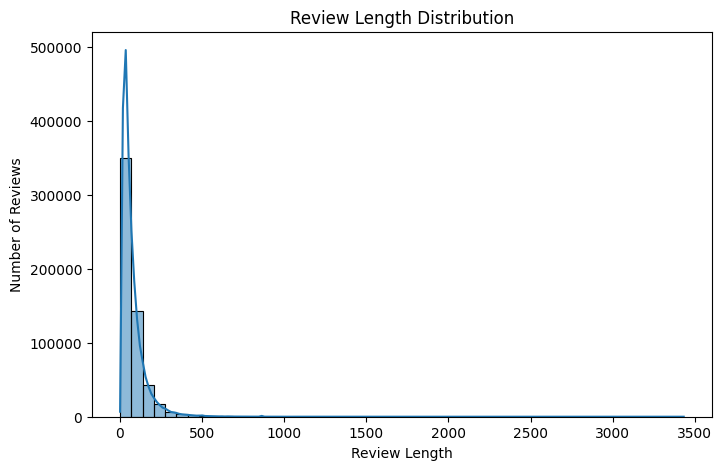

In [ ]:
df["ReviewLength"] = df["Text"].str.split().str.len()
plt.figure(figsize=(8, 5))
sns.histplot(df["ReviewLength"], bins=50, kde=True)
plt.title("Review Length Distribution")
plt.xlabel("Review Length")
plt.ylabel("Number of Reviews")
plt.show()


### **Insights**
1. The tall spike at the far left shows that the large majority of reviews are under about 70 words (the first bar holds about 350k of the 568k reviews). People write a few sentences, not long essays.

2. The counts fall off very fast, and the second bar (about 70 to 140 words) holds only about 140k. By roughly 300 words there are very few reviews left. A few reviews run to more than 3,000 words, which stretches the x-axis to 3500 and flattens everything else into a thin spike.

##**Average Review Length By Rating**

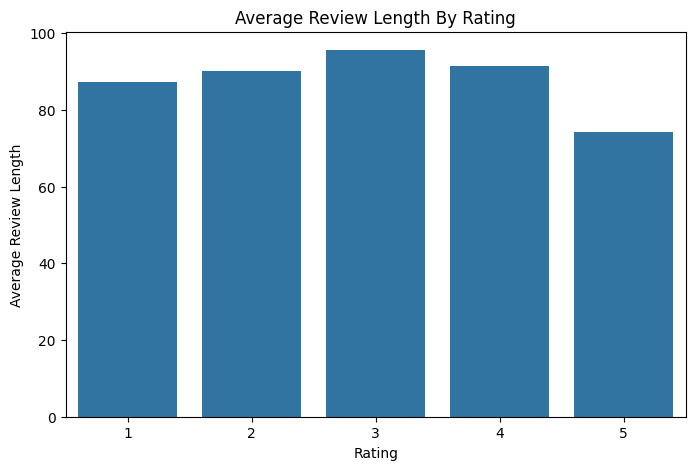

In [ ]:
avg_value = df.groupby("Score")["ReviewLength"].mean()
plt.figure(figsize=(8, 5))
sns.barplot(x=avg_value.index, y=avg_value.values)
plt.title("Average Review Length By Rating")
plt.xlabel("Rating")
plt.ylabel("Average Review Length")
plt.show()

### **Insights**
1. Mixed opinions take more words to explain. A 3-star reviewer usually writes both what they liked and what disappointed them, such as "tastes fine but the packaging was damaged"

2. Happy customers tend to write quick, simple praise like "Great product, will buy again". They don't need to justify anything, so their reviews are brief.

## **Top Review Products**

Text(0, 0.5, 'Number of Reviews')

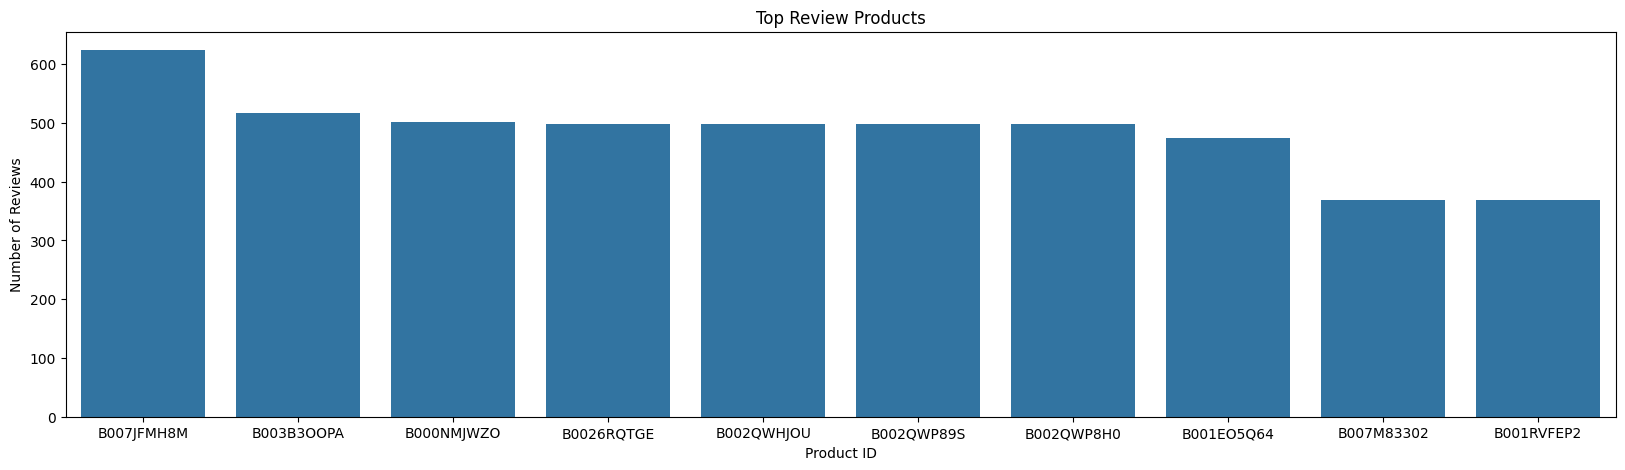

In [ ]:
top_products= df[df['Score']==5]
top_products = top_products['ProductId'].value_counts().head(10)
plt.figure(figsize=(20, 5))
sns.barplot(x=top_products.index, y=top_products.values)
plt.title("Top Review Products")
plt.xlabel("Product ID")
plt.ylabel("Number of Reviews")

### **Insights**
1. B007JFMH8M has about 625 reviews, noticeably more than the next product (about 517). A single product gets far more attention than any other

2. Every product here has between about 370 and 625 reviews. Compared with the dataset's 74,258 products, this is a tiny group, since most products have only a few reviews. Reviews are concentrated on a small number of popular items.

3. Your code still starts with df[df['Score']==5], so these are the products with the most 5-star reviews, not the most-reviewed products overall. The title says "Top Review Products", so either remove the filter to match the title or rename the title:

## **Top Active Users**

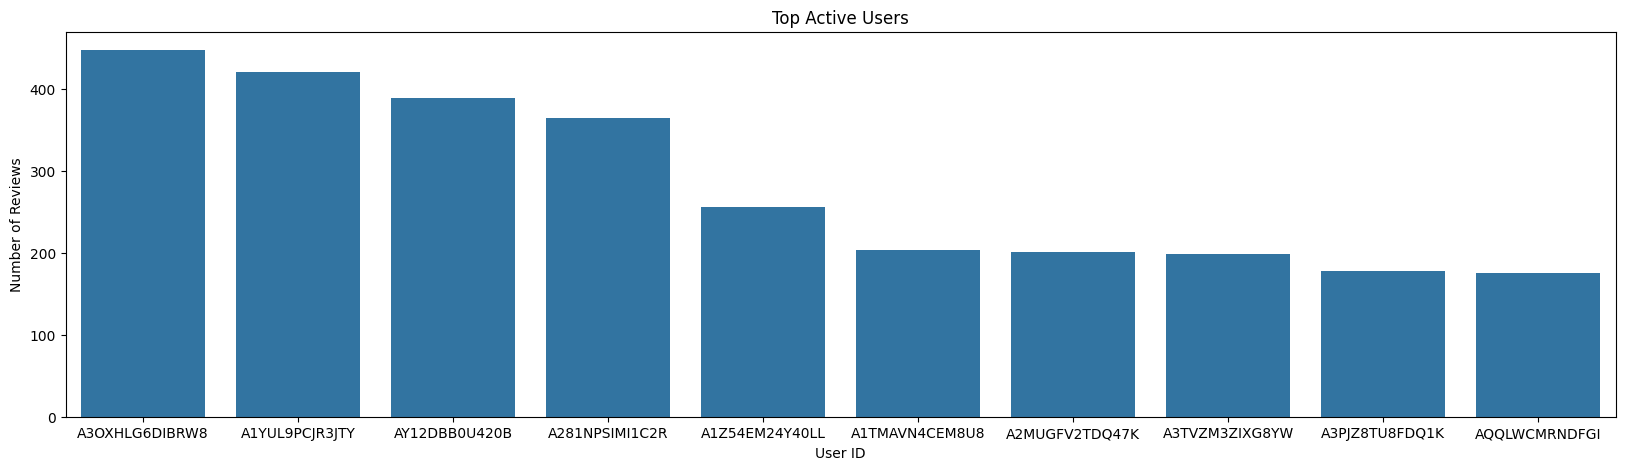

In [ ]:
top_users = df['UserId'].value_counts().head(10)
plt.figure(figsize=(20, 5))
sns.barplot(x=top_users.index, y=top_users.values)
plt.title("Top Active Users")
plt.xlabel("User ID")
plt.ylabel("Number of Reviews")
plt.show()

### **Insights**
1. The most active user (A3OXHLG6DIBRW8) has about 448 reviews, and the top 4 are all above about 365. With about 256,000 users in the dataset, most people write only one or two reviews, so these users are extreme exceptions.

2. The counts go from about 365 to about 256 and then to roughly 175 to 205 for the other six. The top few are in a class of their own, while users 6 to 10 look like a flat group of very active reviewers.

## **Most Common Review Words**

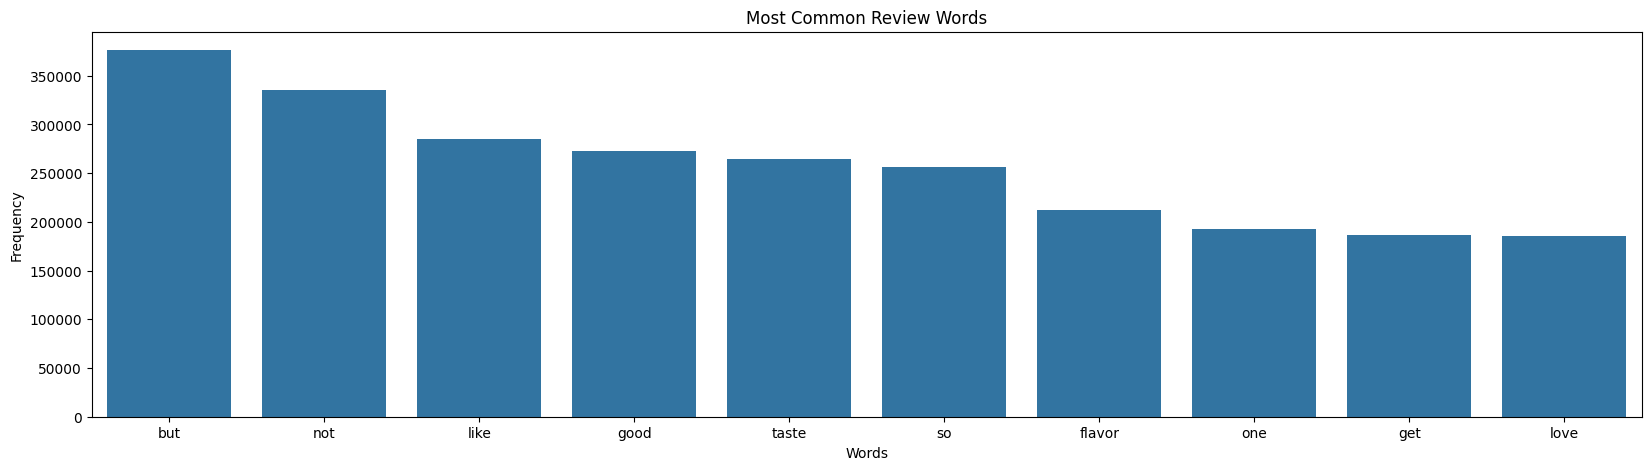

In [ ]:
most_words = pd.Series(" ".join(df["CleanText"]).split()).value_counts().head(10)
plt.figure(figsize=(20, 5))
sns.barplot(x=most_words.index, y=most_words.values)
plt.title("Most Common Review Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.show()

### **Insights**
1. These are the two words we kept out of the stop-word list on purpose. They are the most common words in all English text, so they top the chart even though they carry little topic meaning. The negation word not is the useful one for sentiment.

2. like (about 285k), good (about 273k) and love (about 186k) show that people mostly describe products in simple evaluative language. That fits the dataset, where about 78% of reviews are positive.

In [ ]:
pd.Series(df['Score'].value_counts())*100/len(df['Score']) # As we can see that the 5 rating are more than the remaning rating

,count
Score,
5,63.881309
4,14.189630
1,9.194917
3,7.501394
2,5.232749


In [ ]:
x=df['CleanText']
y=df['Score']

# split (stratify keeps the rating proportions the same in train and test)
x_train,x_text,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

# vectorize (fit on train only)
vectorizer=TfidfVectorizer(max_features=50000,ngram_range=(1,2))
x_train=vectorizer.fit_transform(x_train)
x_test=vectorizer.transform(x_text)

# train the model
model =LogisticRegression(max_iter=1000,class_weight="balanced")
model.fit(x_train,y_train)

# predict
y_pred=model.predict(x_test)

# evaluation meterics
print("Accuracy Score: ",accuracy_score(y_test,y_pred))
print("Precision Score: ",precision_score(y_test,y_pred,average='weighted'))
print("Recall Score: ",recall_score(y_test,y_pred,average='weighted'))



Accuracy Score:  0.731731775758482
Precision Score:  0.7780833042456334
Recall Score:  0.731731775758482
